<a href="https://colab.research.google.com/github/somuenc/FoddHub-Data-Analysis/blob/main/PYF_Project_Learner_Notebook_Full_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Python Foundations: FoodHub Data Analysis

### Context

The number of restaurants in New York is increasing day by day. Lots of students and busy professionals rely on those restaurants due to their hectic lifestyles. Online food delivery service is a great option for them. It provides them with good food from their favorite restaurants. A food aggregator company FoodHub offers access to multiple restaurants through a single smartphone app.

The app allows the restaurants to receive a direct online order from a customer. The app assigns a delivery person from the company to pick up the order after it is confirmed by the restaurant. The delivery person then uses the map to reach the restaurant and waits for the food package. Once the food package is handed over to the delivery person, he/she confirms the pick-up in the app and travels to the customer's location to deliver the food. The delivery person confirms the drop-off in the app after delivering the food package to the customer. The customer can rate the order in the app. The food aggregator earns money by collecting a fixed margin of the delivery order from the restaurants.

### Objective

The food aggregator company has stored the data of the different orders made by the registered customers in their online portal. They want to analyze the data to get a fair idea about the demand of different restaurants which will help them in enhancing their customer experience. Suppose you are hired as a Data Scientist in this company and the Data Science team has shared some of the key questions that need to be answered. Perform the data analysis to find answers to these questions that will help the company to improve the business.

### Data Description

The data contains the different data related to a food order. The detailed data dictionary is given below.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Let us start by importing the required libraries

In [1]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.9/18.9 MB 43.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... canceled
ERROR: Operation cancelled by user


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [3]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

### Understanding the structure of the data

In [4]:
# uncomment and run the below code snippets if the dataset is present in the Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Write your code here to read the data
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FoodHub Project 1 March 2nd/foodhub_order.csv')

In [6]:
# Write your code here to view the first 5 rows
data.head()

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### **Question 1:** How many rows and columns are present in the data? [0.5 mark]

In [7]:
# Write your code here
data.shape

(1898, 9)

#### Observations: There are 1898 Rows and 9 Columns in the data set.


### **Question 2:** What are the datatypes of the different columns in the dataset? (The info() function can be used) [0.5 mark]

In [8]:
# Write your code here
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
- There are total 9 columns out of that 5 are numerical columns and 4 are object type columns.
- The rating column needs to be numerical in order for us to evaluate the different stats about the ratings (example: min, max, mean std etc).
- There are total 1898 rows and no null values in any of the columns.
- Columns restaurent_name, cuisine_type, day_of_the_week needs to be analyzed in order to convert them to string column for drawing better results. (These will be categorical columns for Analysis)


### **Question 3:** Are there any missing values in the data? If yes, treat them using an appropriate method. [1 mark]

In [9]:
# Write your code here
data.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_name,0
cuisine_type,0
cost_of_the_order,0
day_of_the_week,0
rating,0
food_preparation_time,0
delivery_time,0


In [10]:
data.duplicated().sum()

np.int64(0)

#### Observations:
- There are no null values in any of the columns as depicted by the above table.
- There are no duplicated rows in the Dataset.

### **Question 4:** Check the statistical summary of the data. What is the minimum, average, and maximum time it takes for food to be prepared once an order is placed? [2 marks]

In [11]:
# Write your code here
data.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


#### Observations:
- On an average it takes about 27.37 minutes to prepare the food in the restaurent for delivery.
- Minimum and maximum time it takes to prepare the food are 20 and 35 minutes respectively.
- Statistics for Order_Id and customer_id are not of much use and can be removed from the data set or set as object types.
- Food delivery can happen between 35 to 68 minutes after the order has been placed in the app.
- Minimum delivery time is 15 minutes where as it takes 33 minutes max to deliver an order.


### **Question 5:** How many orders are not rated? [1 mark]

In [12]:
# Write the code here
data['rating'].value_counts(normalize=True)

,proportion
rating,
Not given,0.387777
5,0.309800
4,0.203372
3,0.099052


In [13]:
data.groupby('rating')['order_id'].count()

,order_id
rating,
3,188
4,386
5,588
Not given,736


#### Observations:
- As per the value counts there are total 736 records where rating is not given for an order.
- Because of this reason only rating column instead of int or float, it has been converted to object type.
- We might have to analyse and update this rating of 'Not given' to NaN and convert the column to numeric


### Exploratory Data Analysis (EDA)

### Univariate Analysis

### **Question 6:** Explore all the variables and provide observations on their distributions. (Generally, histograms, boxplots, countplots, etc. are used for univariate exploration.) [9 marks]

In [14]:
# Write the code here
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


In [15]:
data.shape

(1898, 9)

In [16]:
data.describe()

,order_id,customer_id,cost_of_the_order,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,35.000000,33.000000


**Observation on Cost of the Order using Histplot and boxplot**

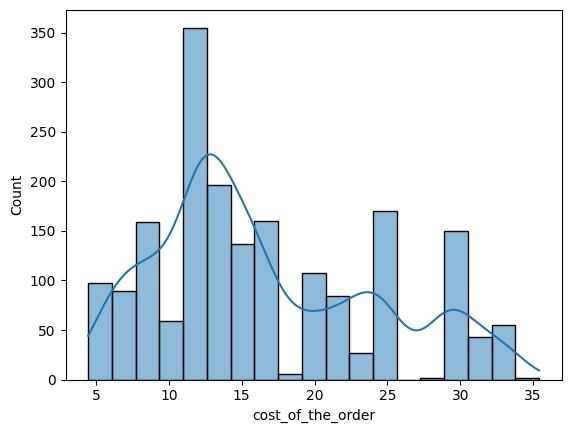

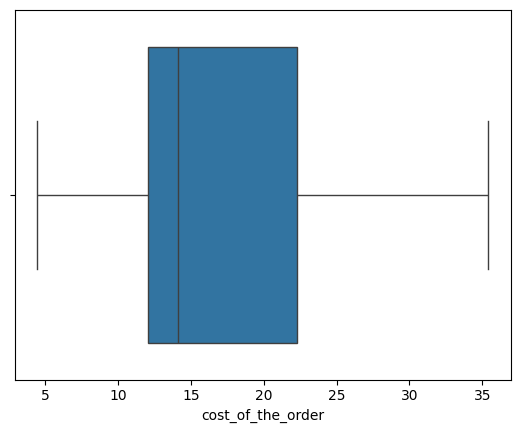

In [17]:
# lets look at the cost of the order distribution
sns.histplot(data=data,x='cost_of_the_order', kde=True)
plt.show()
sns.boxplot(data=data,x='cost_of_the_order')
plt.show()

* Cost of the order is right skewed and distribution is not symmetrical.
* There is increase in cost and number of orders to some extent, distribution goes up and down twice.
* As seen from the boxplot there seems to be no outliers in this distribution.

**Observation on Food Preparation time**

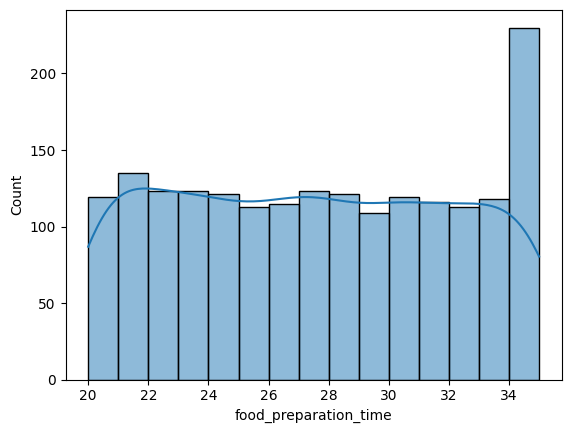

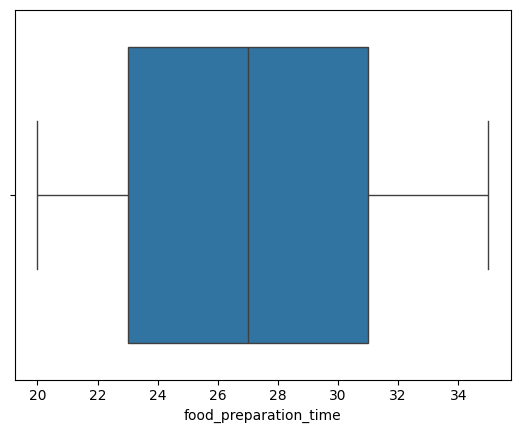

In [18]:
# lets look distribution of food preparation time
sns.histplot(data=data,x='food_preparation_time', bins=15, kde=True)
plt.show()
sns.boxplot(data=data,x='food_preparation_time')
plt.show()

* Food preparation distribution is ideal as it has no outliers.
* As seen from the boxplot that Mean and Median are very close to each other hence ditribution is symmetric.
* Food preparation time ranges from 23 minutes to 31 minutes.

**Observation on Food delivery time**

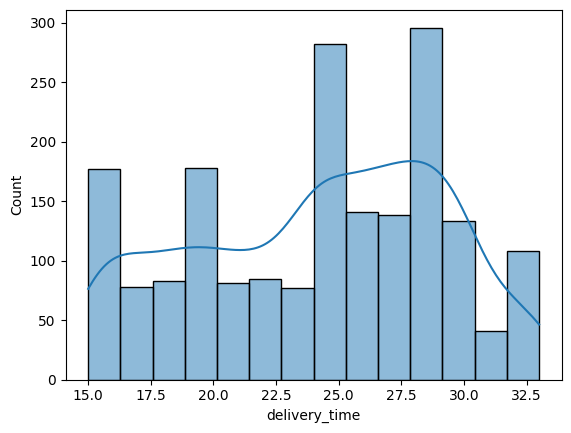

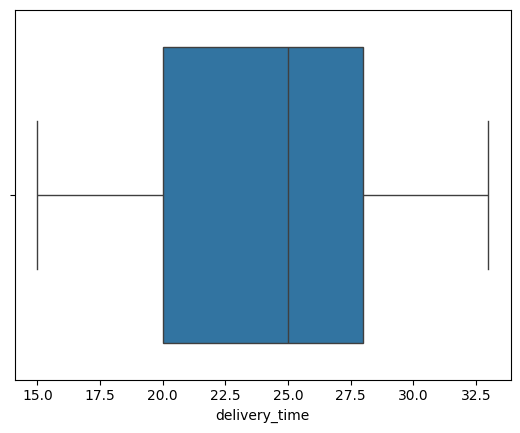

In [19]:
# lets look at the distribution of food delivery time
sns.histplot(data=data,x='delivery_time', kde=True)
plt.show()
sns.boxplot(data=data,x='delivery_time')
plt.show()

* Distribution of delivery time is left skewed and as can be seen from the plot there are not out liers.
* This needs to be analysed along with Cuisine type and day of the week to better understand the increase in delivery time.
* Food delivery time ranges from 20 to 28 minutes.

**Observation on Cuisine Type**

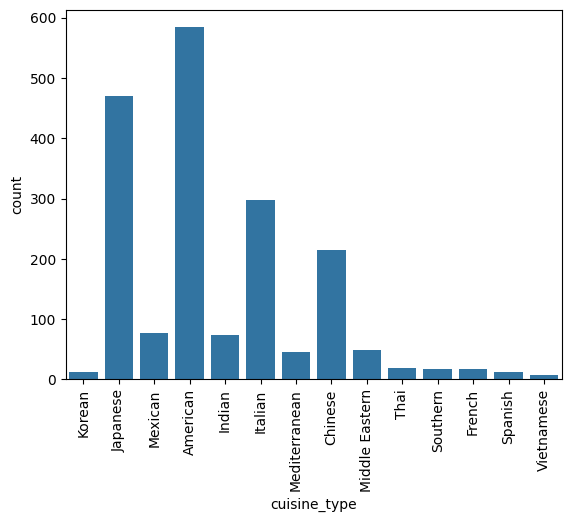

In [20]:
# lets check on cuisine type distribution
sns.countplot(data=data,x='cuisine_type')
plt.xticks(rotation=90)
plt.show()

* Looking at the observation there are only 4 main contributors to the orders in terms of the delivery American, Japanese, Italian followed by Chinese.

In [21]:
# lets see the count of orders for each cuisine type and sort them in descending order
data.groupby('cuisine_type')['order_id'].count().sort_values(ascending=False)

,order_id
cuisine_type,
American,584
Japanese,470
Italian,298
Chinese,215
Mexican,77
Indian,73
Middle Eastern,49
Mediterranean,46
Thai,19


* As can be seen by the order counts based on the cuisine type, top providers are American, Japanese, Italian and Chinese.
* Very likely used restaurents are Vietnamese, Spanish, Korean, Southern etc...

**Observations on Day of the week**

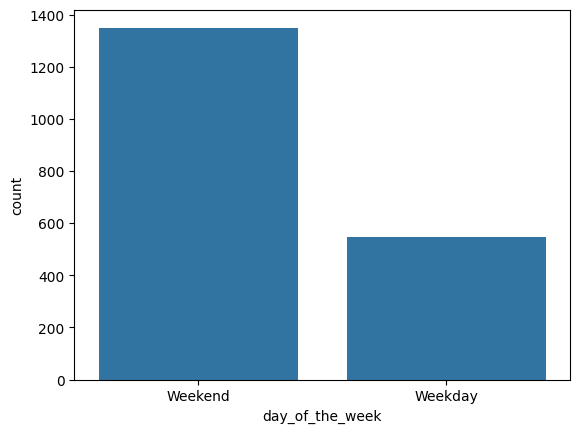

In [22]:
# lets check day of the week distribution using count plot
sns.countplot(data=data,x='day_of_the_week')
plt.show()

* Its evident that Weekend orders double out compared to Week Day orders in these restaurents.

**Observation on rating**

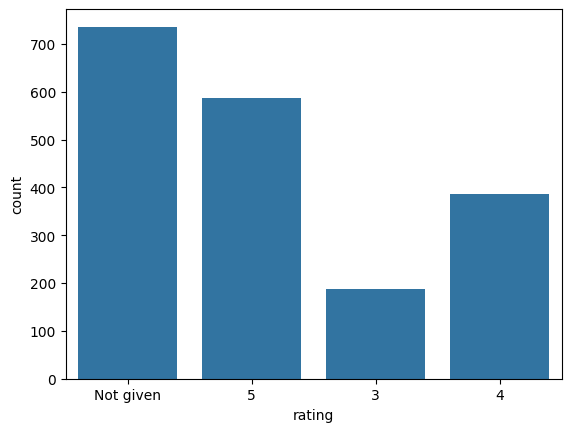

In [23]:
sns.countplot(data=data,x='rating')
plt.show()

* More than 39% of the orders doesnt have rating provided by the customers

In [24]:
# lets look at the count and percentage
data['rating'].value_counts(normalize=True)

,proportion
rating,
Not given,0.387777
5,0.309800
4,0.203372
3,0.099052


* As observed in the counts from the above about 39% of the orders doesnt have rating.

### **Question 7**: Which are the top 5 restaurants in terms of the number of orders received? [1 mark]

In [25]:
# Write the code here
# Top 5 restaurents
data.groupby('restaurant_name')['order_id'].count().sort_values(ascending=False).head(5)
# bottom 5 restaurents
# data.groupby('restaurant_name')['order_id'].count().sort_values(ascending=False).tail(5)

,order_id
restaurant_name,
Shake Shack,219
The Meatball Shop,132
Blue Ribbon Sushi,119
Blue Ribbon Fried Chicken,96
Parm,68


#### Observations:
- Shake Shack is the restaurent with most orders of 219.
- Parm has received about 68 orders and is in 5th position in terms of orders.


### **Question 8**: Which is the most popular cuisine on weekends? [1 mark]

In [26]:
# Write the code here
data[data['day_of_the_week'] == 'Weekend'].groupby('day_of_the_week')['cuisine_type'].value_counts()

day_of_the_week  cuisine_type  
Weekend          American          415
                 Japanese          335
                 Italian           207
                 Chinese           163
                 Mexican            53
                 Indian             49
                 Mediterranean      32
                 Middle Eastern     32
                 Thai               15
                 French             13
                 Korean             11
                 Southern           11
                 Spanish            11
                 Vietnamese          4
Name: count, dtype: int64

#### Observations:
 - Most popular cuisine over the weekend is American.
 - Based on the data looks like most second popular cuisines belongs to Asia as can be seen from the dataset like Japanese, Chinese, Indian.


### **Question 9**: What percentage of the orders cost more than 20 dollars? [2 marks]

In [27]:
# Write the code here
orders_costing_morethan_20_dollar = data[data['cost_of_the_order'] > 20].shape[0]
total_orders = data.shape[0]
print(f'Total Orders in the dataset: {total_orders}')
print(f'Orders costing more than $20: {orders_costing_morethan_20_dollar}')
percentage_of_orders = (orders_costing_morethan_20_dollar / total_orders) * 100
print(f"Percentage of orders costing more than $20: {percentage_of_orders:.2f}%")


Total Orders in the dataset: 1898
Orders costing more than $20: 555
Percentage of orders costing more than $20: 29.24%


#### Observations:
 - Out of the total 1898 orders, 555 are orders which costs more than dollar 20.
 - That means about 29.24% of orders are costing more than $20.
 - As seen in the univariate analysis most of the orders contributed were less than dollar 20.


### **Question 10**: What is the mean order delivery time? [1 mark]

In [28]:
# Write the code here
# data.describe().loc['mean', 'delivery_time']
data['total_time'] = data['food_preparation_time'] + data['delivery_time']
data['total_time'].mean()

np.float64(51.53371970495258)

#### Observations:
* That means it takes about 51.5 minutes on average to deliver an order once its placed in the app. This is the average time taken for any order to be delivered to Customer after the order is placed in the app.


### **Question 11:** The company has decided to give 20% discount vouchers to the top 3 most frequent customers. Find the IDs of these customers and the number of orders they placed. [1 mark]

In [29]:
# Write the code here
data.groupby('customer_id')['order_id'].count().sort_values(ascending=False).head(3)
# data[data['customer_id'] == 52832]['rating'].count()
# data[data['customer_id'] == 47440]['order_id'].count()
# data[data['customer_id'] == 83287]['order_id'].count()

,order_id
customer_id,
52832,13
47440,10
83287,9


#### Observations:
- There are 13 orders from customer with Id 52832.
- 47440 has total 10 orders on his name.
- Third customer has 9 orders in total.
- Above 3 can be given 20% discount on their next order.


### Multivariate Analysis

### **Question 12**: Perform a multivariate analysis to explore relationships between the important variables in the dataset. (It is a good idea to explore relations between numerical variables as well as relations between numerical and categorical variables) [10 marks]


## Observation on Relation between numerical variables

In [30]:
# Write the code here
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
 9   total_time             1898 non-null   int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 148.4+ KB


In [31]:
# convert the not given rating to NAN so that we can analyse rating column as numerical column
data.replace({'rating': 'Not given'}, np.nan, inplace=True)
data['rating'] = data['rating'].astype(float)

In [32]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1162 non-null   float64
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
 9   total_time             1898 non-null   int64  
dtypes: float64(2), int64(5), object(3)
memory usage: 148.4+ KB


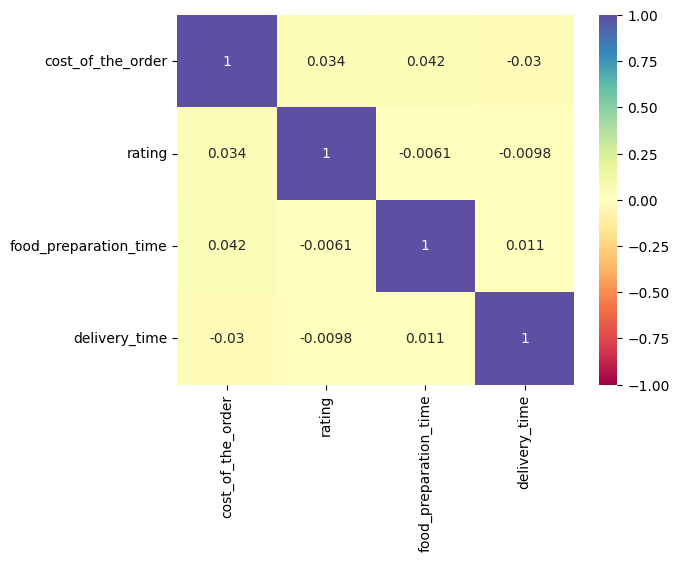

In [33]:
# dropping of order_id and customer_id from the analysis since they wont add value to our analysis
numerical_columns = ['cost_of_the_order', 'rating', 'food_preparation_time', 'delivery_time']
corr_matrix = data[numerical_columns].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Spectral',vmin=-1,vmax=1)
plt.show()

* As can be seen from the heatmap that non of the numerical columns have strong relation among them.

## Lets explore bivariate relationships between two variables to see any strong relations

### Delivery Time by Cuisine Type

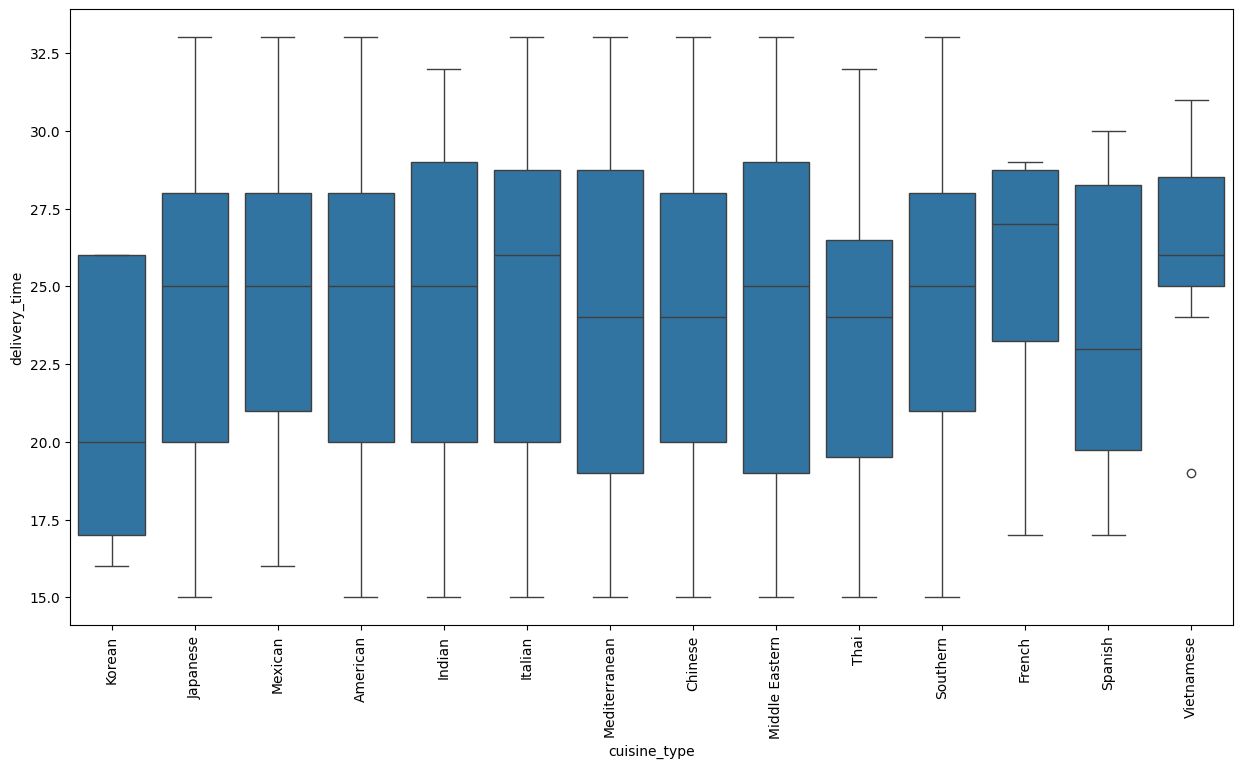

In [34]:
# lets draw a boxplot
plt.figure(figsize=(15,8))
sns.boxplot(data=data,x='cuisine_type',y='delivery_time')
plt.xticks(rotation=90)
plt.show()

* no strong relation between delivery time and restaurent type.
* As seen Korean cuisine type takes about 15 to 26 mnts to deliver the food
* Where as Vietnamese cuisine type takes about 26-28 mnts to deliver the food.

### Delivery time by Restaurent Name

In [35]:
# lets draw relation between Delivery time and restaurent name
# cleaning up the restaurent name since there are warnings due to special charecters in the name
import re

def remove_non_ascii(text):
    """Removes non-ASCII characters from a string."""
    return re.sub(r'[^\x00-\x7F]+', '', text)

data['restaurant_name_cleaned'] = data['restaurant_name'].apply(remove_non_ascii)

# Let's check some of the original and cleaned names to see the effect
print("Original vs. Cleaned Restaurant Names (first 10 unique):")
for original, cleaned in data[['restaurant_name', 'restaurant_name_cleaned']].drop_duplicates().head(10).values:
    print(f"Original: '{original}' -> Cleaned: '{cleaned}'")

Original vs. Cleaned Restaurant Names (first 10 unique):
Original: 'Hangawi' -> Cleaned: 'Hangawi'
Original: 'Blue Ribbon Sushi Izakaya' -> Cleaned: 'Blue Ribbon Sushi Izakaya'
Original: 'Cafe Habana' -> Cleaned: 'Cafe Habana'
Original: 'Blue Ribbon Fried Chicken' -> Cleaned: 'Blue Ribbon Fried Chicken'
Original: 'Dirty Bird to Go' -> Cleaned: 'Dirty Bird to Go'
Original: 'Tamarind TriBeCa' -> Cleaned: 'Tamarind TriBeCa'
Original: 'The Meatball Shop' -> Cleaned: 'The Meatball Shop'
Original: 'Barbounia' -> Cleaned: 'Barbounia'
Original: 'Anjappar Chettinad' -> Cleaned: 'Anjappar Chettinad'
Original: 'Bukhara Grill' -> Cleaned: 'Bukhara Grill'


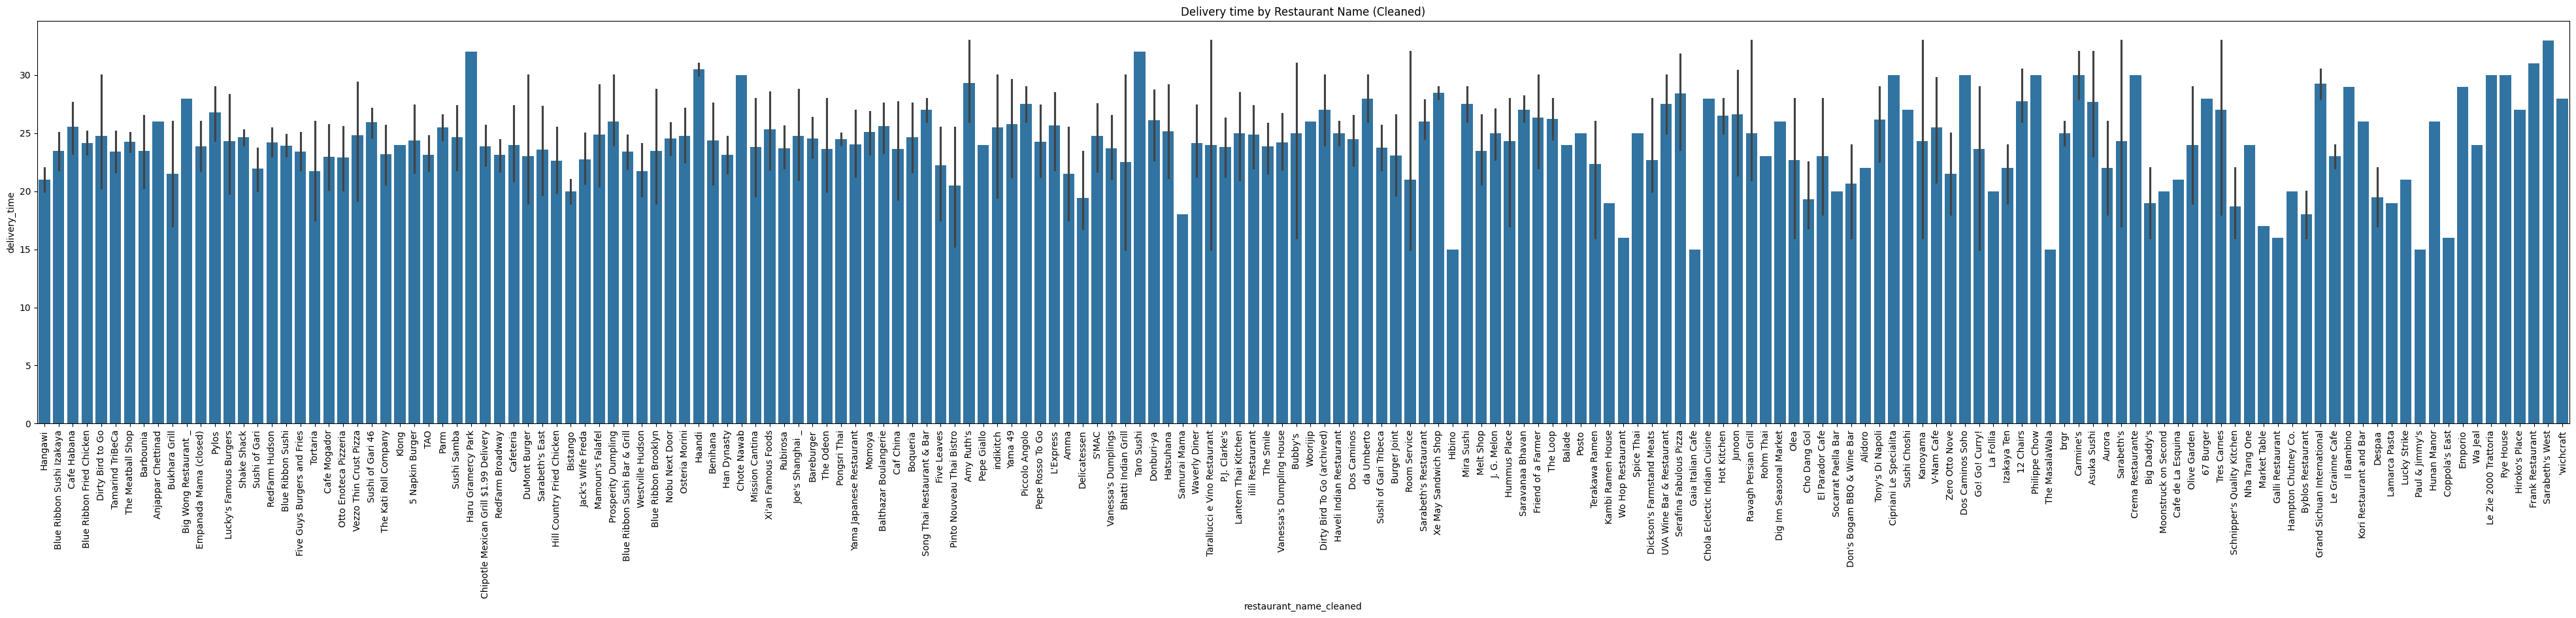

In [36]:
# lets draw relation between Delivery time and restaurent name
plt.figure(figsize=(50,8))
sns.barplot(data=data,x='restaurant_name_cleaned',y='delivery_time') # Use the cleaned column
plt.xticks(rotation=90)
plt.title("Delivery time by Restaurant Name (Cleaned)")
plt.show();

* not much strong corelation between Delivery time and restaurent name
* but most of the restaurents take similar time for delivery except few of the restaurents.

### Delivery Time by day of the week

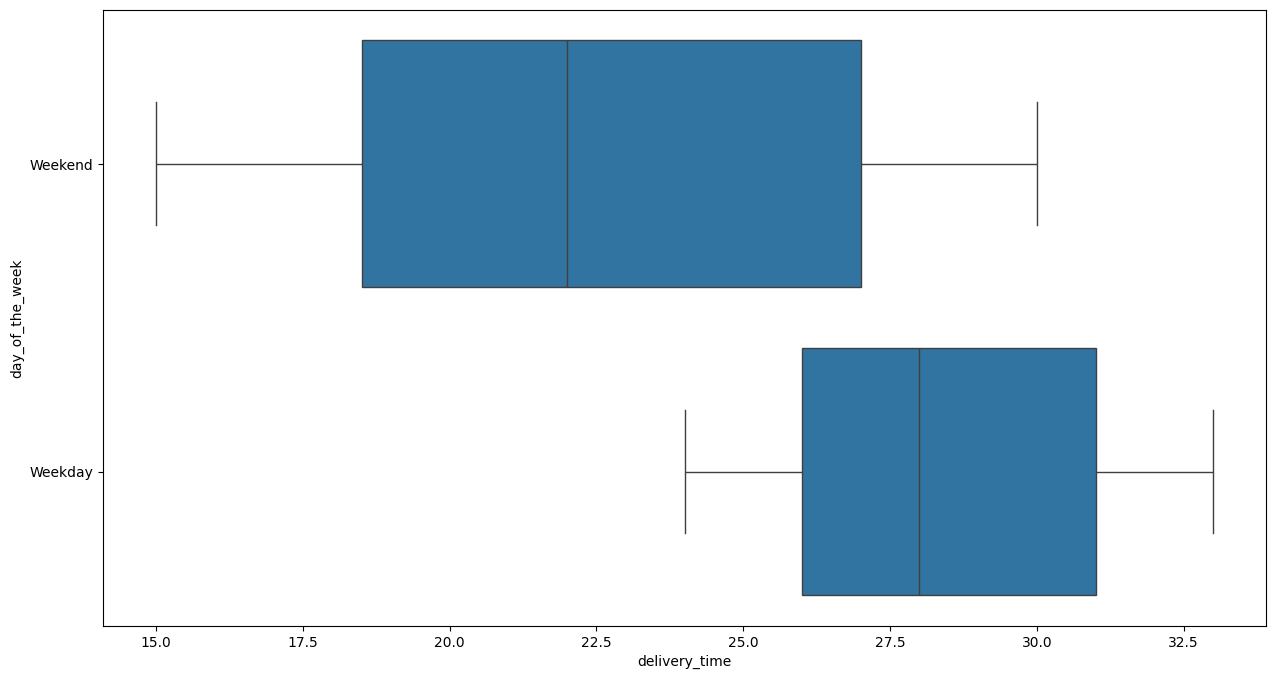

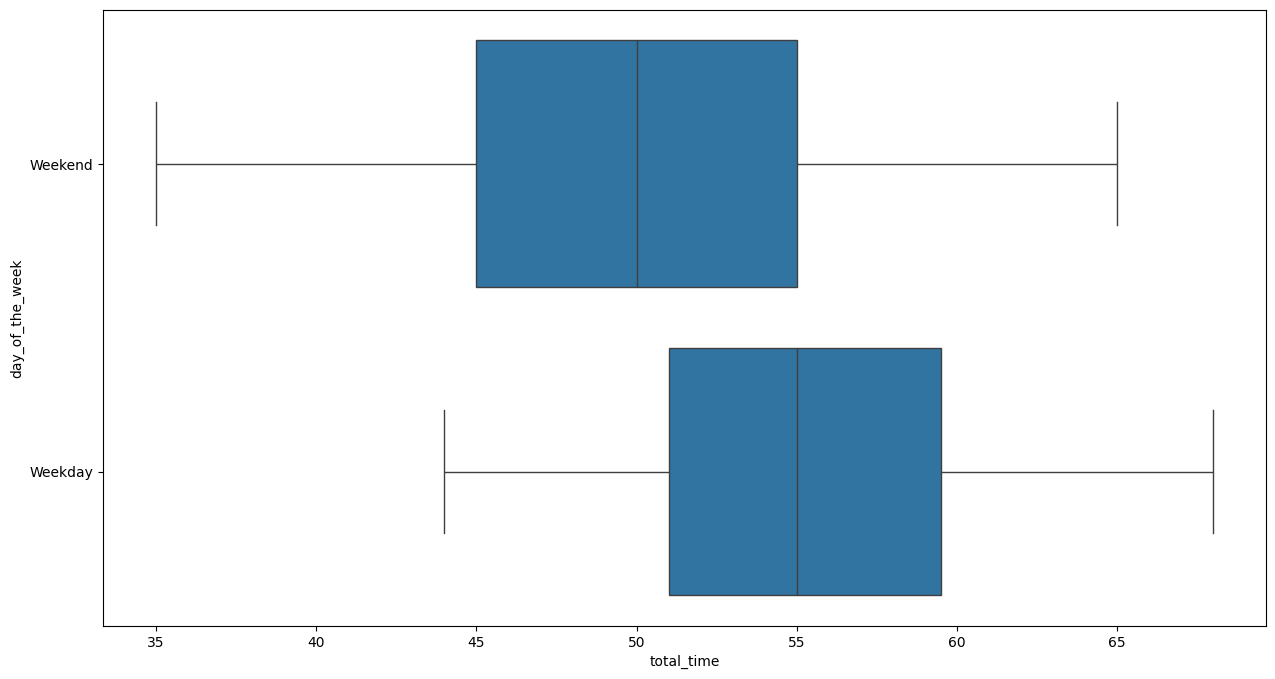

In [37]:
plt.figure(figsize=(15,8))
sns.boxplot(data=data,y='day_of_the_week', x='delivery_time')
plt.show()
plt.figure(figsize=(15,8))
sns.boxplot(data=data,y='day_of_the_week', x='total_time')
plt.show()

* Week end orders takes about 18-27 mnts for delivery
* Week day orders takes about 26 to 31 mnts for delivery
* Week end orders takes about 45-55 minutes overall to deliver an order where as it takes about 51-59 minutes to deliver during the week day.

## Cost of the order versus cuisine type

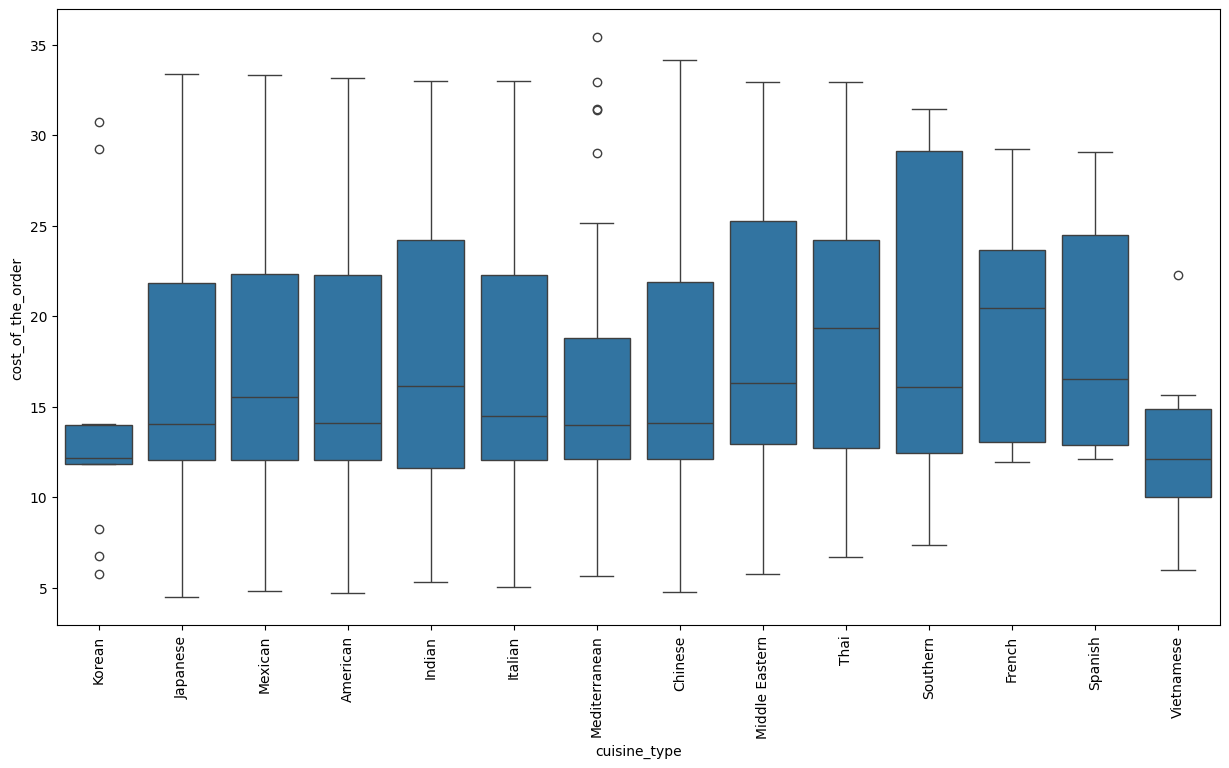

In [38]:
plt.figure(figsize=(15,8))
sns.boxplot(data=data,x='cuisine_type',y='cost_of_the_order')
plt.xticks(rotation=90)
plt.show()

* Southern cuisine type is feels to be costlier than others.

### Order cost across the day of the week

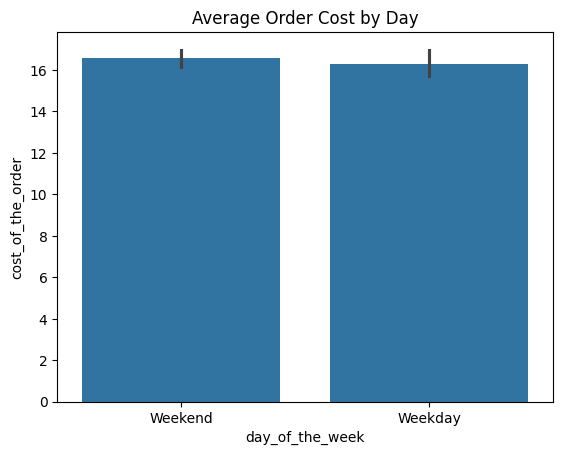

In [39]:
sns.barplot(data=data, x='day_of_the_week', y='cost_of_the_order')
plt.title("Average Order Cost by Day");

Not much relation between these variables

## Ratings across cuisins

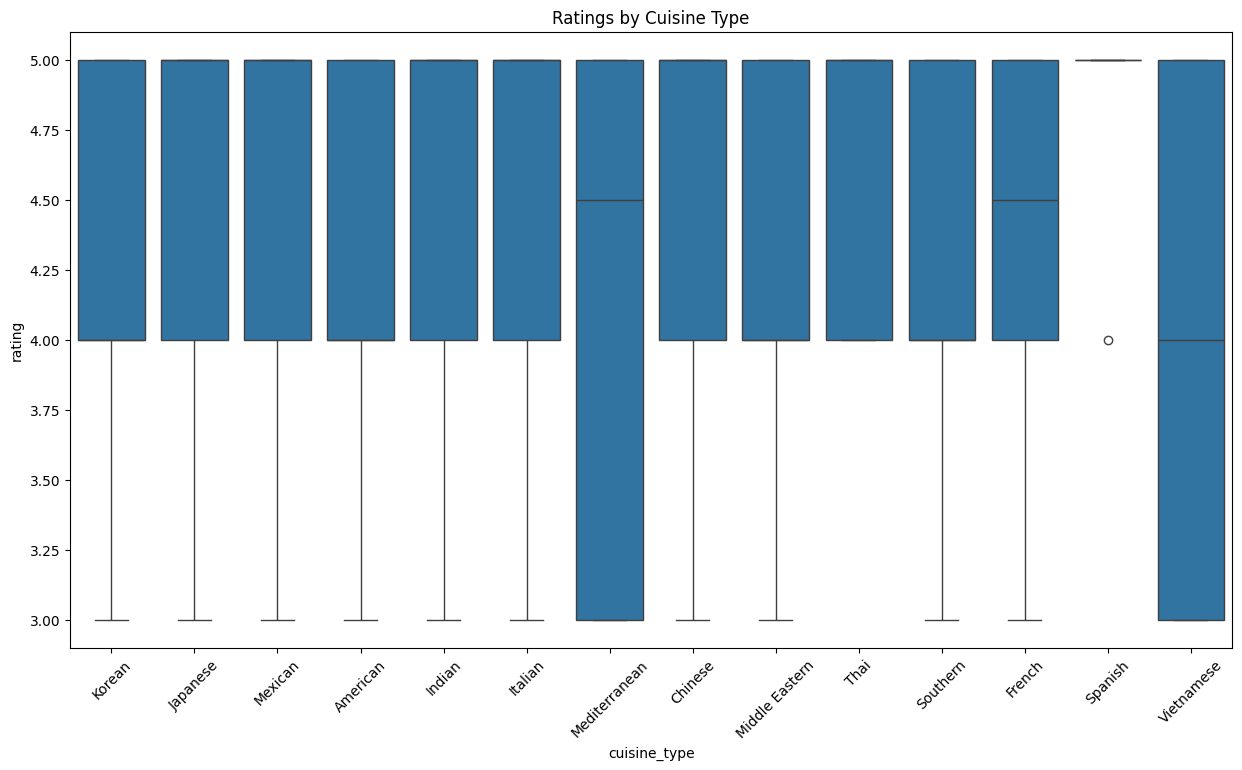

In [40]:
plt.figure(figsize=(15,8))
sns.boxplot(data=data, x='cuisine_type', y='rating')
plt.xticks(rotation=45)
plt.title("Ratings by Cuisine Type");

* No strong relation between ratings across Cusines
* Average rating for Vietnamese and Mediterranean is low compared to other cuisine types.

## Ratings across Restaurents

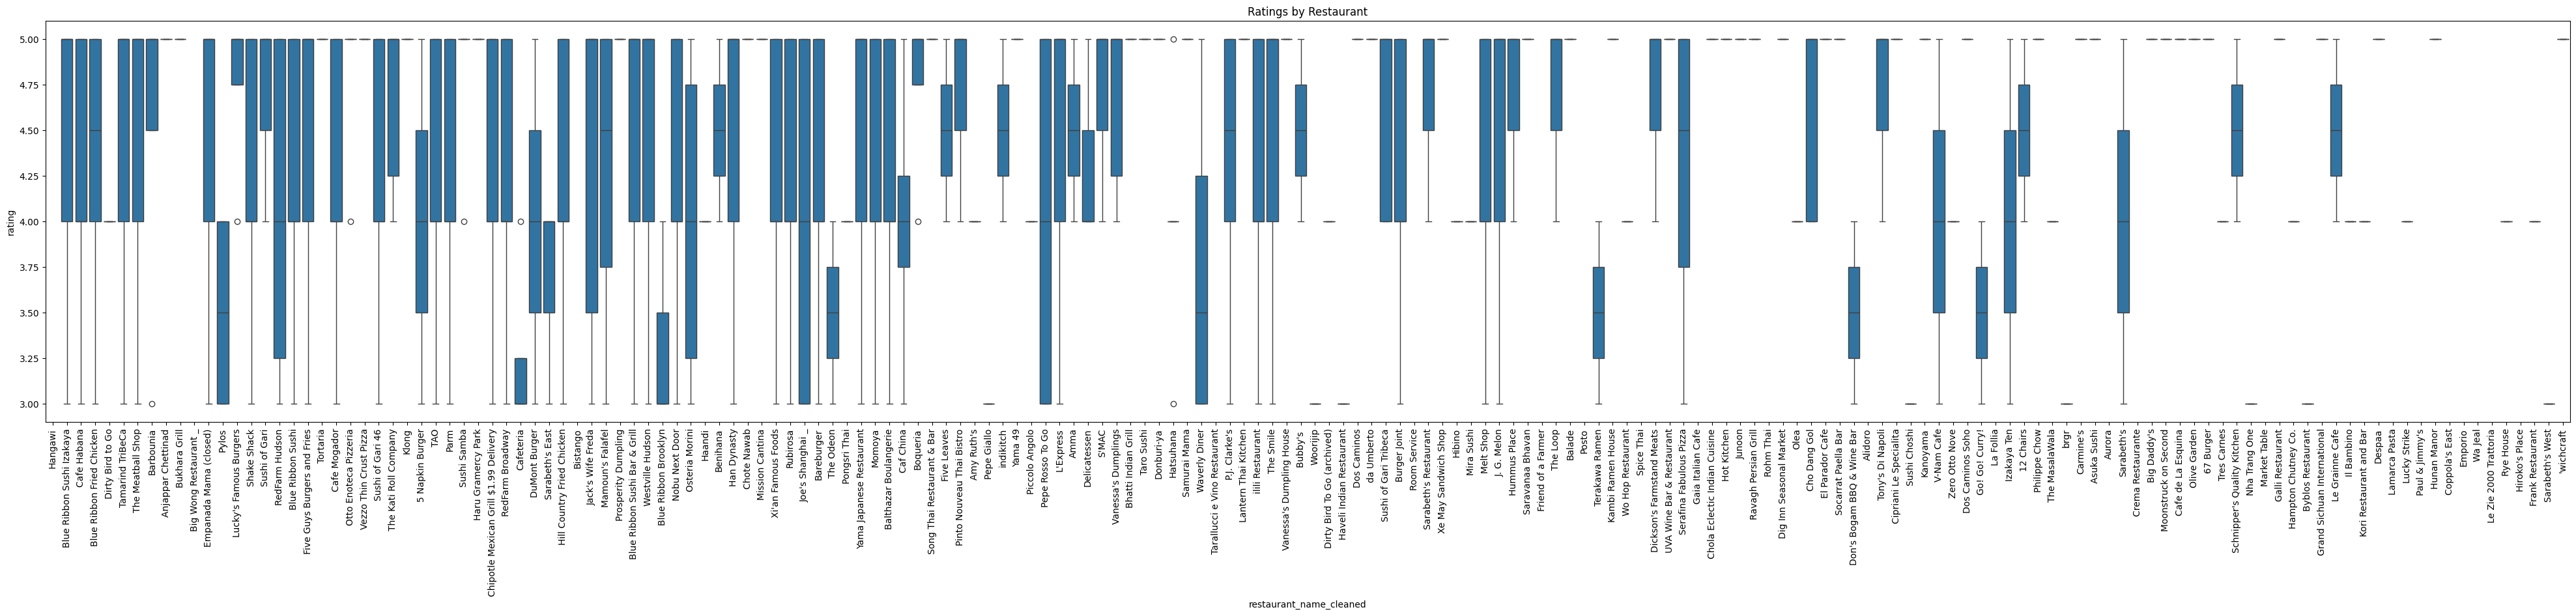

In [41]:
# lets use the cleaned restaurent name
plt.figure(figsize=(50,8))
sns.boxplot(data=data, x='restaurant_name_cleaned', y='rating')
plt.xticks(rotation=90)
plt.title("Ratings by Restaurant");

# Multivariate Analysis

## Delivery time by Cuisine Type and day of week


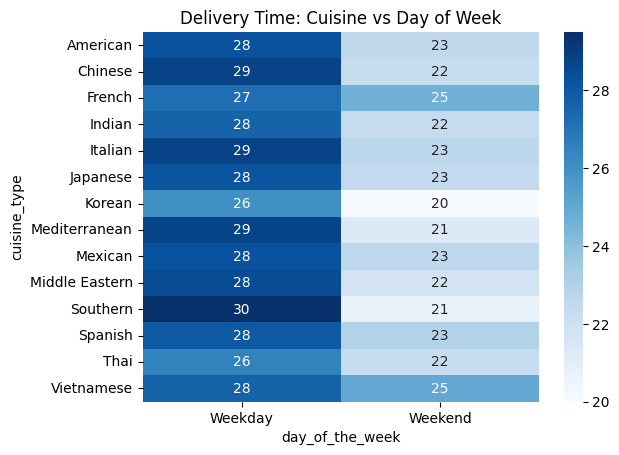

In [42]:
pivot = data.pivot_table(values='delivery_time',
                       index='cuisine_type',
                       columns='day_of_the_week',
                       aggfunc='mean')

sns.heatmap(pivot, annot=True, cmap='Blues')
plt.title("Delivery Time: Cuisine vs Day of Week");

* As seen from the plot, most restaurents take more time in week day vs week end.
* Another observation is, Most popular restaurents take more time to deliver the food. Examples are American, Chinese and Italian

## Cost by restaurent x Cuisine type

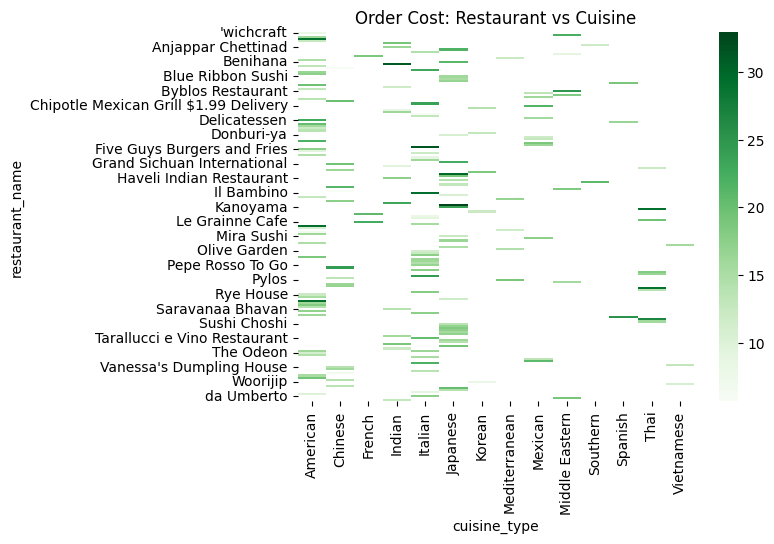

In [43]:
pivot = data.pivot_table(values='cost_of_the_order',
                       index='restaurant_name',
                       columns='cuisine_type',
                       aggfunc='mean')

sns.heatmap(pivot, cmap='Greens')
plt.title("Order Cost: Restaurant vs Cuisine");

## Pairplot to draw relation between numerical variables in the dataset

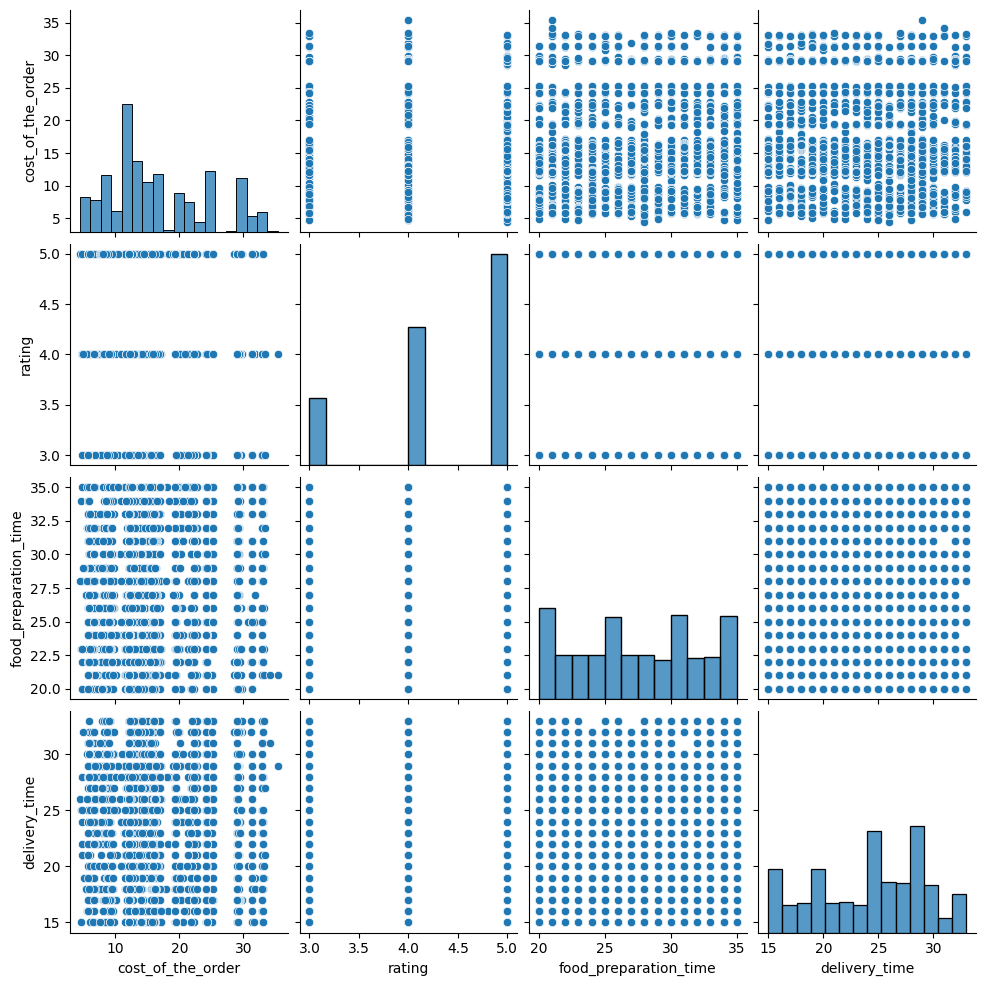

In [44]:
sns.pairplot(data=data, vars=numerical_columns);

* No correlation between numerical variables of the data set.

## Find out relation between numerical and day of the week column


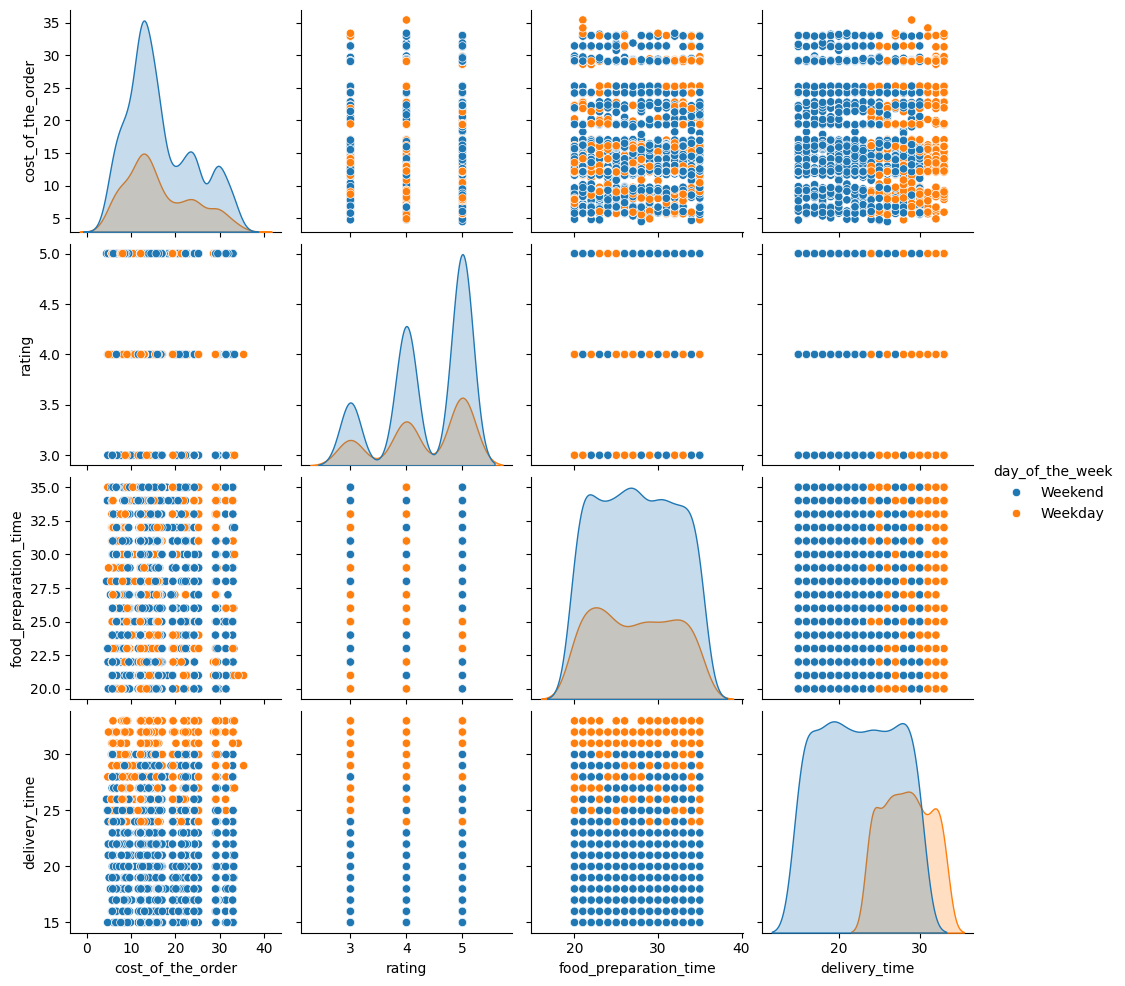

In [45]:
sns.pairplot(data=data, vars=numerical_columns, hue='day_of_the_week');

Not much observations from the plot.

### Find relation between numerical and Cuisine type column

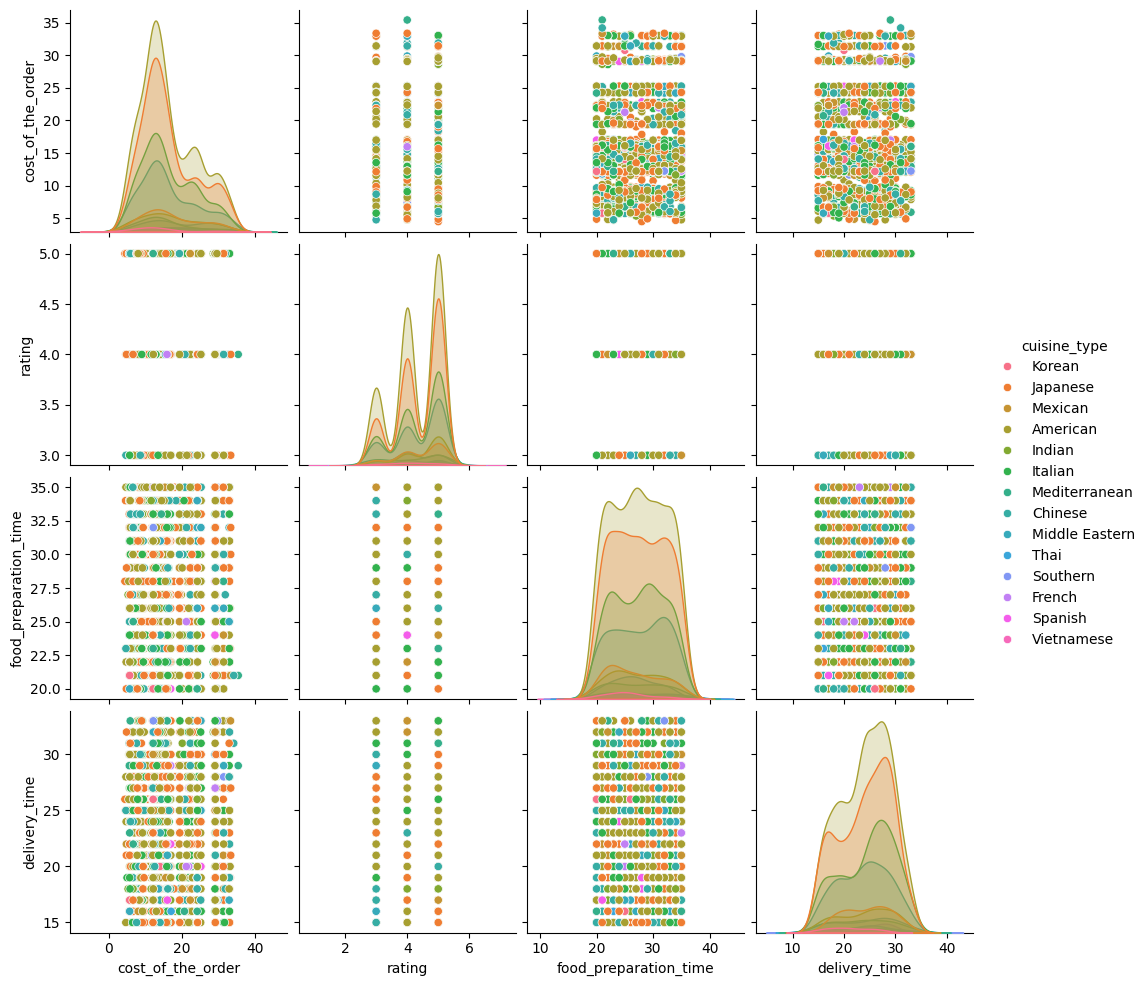

In [46]:
sns.pairplot(data=data, vars=numerical_columns, hue='cuisine_type');

* Food preparation and Food delivery times are more for top restaurents as the demand is more in those restaurents ex: American, Chinese, Italian and Indian

### **Question 13:** The company wants to provide a promotional offer in the advertisement of the restaurants. The condition to get the offer is that the restaurants must have a rating count of more than 50 and the average rating should be greater than 4. Find the restaurants fulfilling the criteria to get the promotional offer. [3 marks]

In [47]:
# Write the code here
# lets check unique values from rating column
data['rating'].unique()

array([nan,  5.,  3.,  4.])

#### Observations:
* As seen rating column is of object type because of 'Not given' text as one of the rating values.
* we need to replace 'Not given' rating to nan and convert rating column to float to do further analyses.


In [48]:
# lets convert 'Not Given' to nan and convert rating to float column
data['rating'] = data['rating'].replace('Not given', np.nan)
data['rating'] = data['rating'].astype('float')
data['rating'].value_counts()

,count
rating,
5.0,588
4.0,386
3.0,188


In [49]:
# Calculate rating counts and average ratings for each restaurant
restaurant_ratings = data.groupby('restaurant_name')['rating'].agg(
    count_rating='count',
    avg_rating='mean'
).reset_index()

# Filter restaurants based on the criteria: rating count > 50 AND average rating > 4
promotional_restaurants = restaurant_ratings[
    (restaurant_ratings['count_rating'] > 50) &
    (restaurant_ratings['avg_rating'] > 4)
]

# # Display the names of these restaurants
print("Restaurants eligible for promotional offer:")
print(promotional_restaurants)

Restaurants eligible for promotional offer:
               restaurant_name  count_rating  avg_rating
20   Blue Ribbon Fried Chicken            64    4.328125
21           Blue Ribbon Sushi            73    4.219178
136                Shake Shack           133    4.278195
153          The Meatball Shop            84    4.511905


* As observed from the above there are only 4 restaurents with rating count of more than 50 for rating of 4 or more
* Shake Shack has the highest count of ratings where as The Meatball shop has highest rating.

### **Question 14:** The company charges the restaurant 25% on the orders having cost greater than 20 dollars and 15% on the orders having cost greater than 5 dollars. Find the net revenue generated by the company across all orders. [3 marks]

# Find out the Profit of the Company

In [50]:
# Write the code here
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 1898 non-null   int64  
 1   customer_id              1898 non-null   int64  
 2   restaurant_name          1898 non-null   object 
 3   cuisine_type             1898 non-null   object 
 4   cost_of_the_order        1898 non-null   float64
 5   day_of_the_week          1898 non-null   object 
 6   rating                   1162 non-null   float64
 7   food_preparation_time    1898 non-null   int64  
 8   delivery_time            1898 non-null   int64  
 9   total_time               1898 non-null   int64  
 10  restaurant_name_cleaned  1898 non-null   object 
dtypes: float64(2), int64(5), object(4)
memory usage: 163.2+ KB


In [51]:
restaurents_with_cost_greater_than_20 = data[data['cost_of_the_order'] > 20]
restaurents_with_cost_greater_than_5 = data[(data['cost_of_the_order'] > 5) & (data['cost_of_the_order'] <= 20)]
total_profit_from_orders_greater_than_20 = restaurents_with_cost_greater_than_20['cost_of_the_order'].sum() * 0.25
total_profit_from_orders_greater_than_5 = restaurents_with_cost_greater_than_5['cost_of_the_order'].sum() * 0.1
print(f'profit from orders costing more than 20$ = {total_profit_from_orders_greater_than_20} for $5 = {total_profit_from_orders_greater_than_5} Total Profit = {total_profit_from_orders_greater_than_5+total_profit_from_orders_greater_than_20}')

profit from orders costing more than 20$ = 3688.7275 for $5 = 1651.7170000000003 Total Profit = 5340.4445000000005


#### Observations:
* As seen by the above code, profit from Orders costing more than 20$ is 3688
* Profit for orders costing between dollar 5 - 20 is 1651 dollar
* Hence total profit is dollar 5340.


### **Question 15:** The company wants to analyze the total time required to deliver the food. What percentage of orders take more than 60 minutes to get delivered from the time the order is placed? (The food has to be prepared and then delivered.) [2 marks]

In [52]:
# Write the code here
data['total_time_taken_to_deliver_food'] = data['food_preparation_time'] + data['delivery_time']
orders_taking_more_than_60_minutes = data[data['total_time_taken_to_deliver_food'] > 60].shape[0]
total_orders = data.shape[0]
print(f'Total Orders in the dataset: {total_orders}')
print(f'Orders taking more than 60 minutes: {orders_taking_more_than_60_minutes}')
print(f'Percentage of Orders taking more than 60 minutes to deliver food: {(orders_taking_more_than_60_minutes/total_orders)*100}')


Total Orders in the dataset: 1898
Orders taking more than 60 minutes: 200
Percentage of Orders taking more than 60 minutes to deliver food: 10.537407797681771


#### Observations:
* There are about 10% of orders taking more than 60 minutes to deliver the food.
* Additionally there are about 81 week end orders and 119 weekday orders.


In [53]:
week_end_orders = data[(data['day_of_the_week'] == 'Weekend') & (data['total_time_taken_to_deliver_food'] > 60)]
week_day_orders = data[(data['day_of_the_week'] == 'Weekday') & (data['total_time_taken_to_deliver_food'] > 60)]
print(f'Total Week End Orders: {week_end_orders.shape[0]}')
print(f'Total Week Day Orders: {week_day_orders.shape[0]}')

Total Week End Orders: 81
Total Week Day Orders: 119


### **Question 16:** The company wants to analyze the delivery time of the orders on weekdays and weekends. How does the mean delivery time vary during weekdays and weekends? [2 marks]

In [54]:
# Write the code here
data.groupby('day_of_the_week')['delivery_time'].mean()

,delivery_time
day_of_the_week,
Weekday,28.340037
Weekend,22.470022


#### Observations:
* As seen from the Average delivery time, Its more in comparision to Week End orders. Traffic over the week end is less hence we have less weekend delivery time.


### Conclusion and Recommendations

### **Question 17:** What are your conclusions from the analysis? What recommendations would you like to share to help improve the business? (You can use cuisine type and feedback ratings to drive your business recommendations.) [6 marks]

### Conclusions:
* About 39% of the orders are not rated by the customers.
* Average Cost of the orders is 14 dollars.
* Food Preparation Time is Symmetrical and has no outliers.
* Food Delivery Time is right skewed and has an average of 25 minutes.
* Top Contributors for the orders are American, Japanese, Italian followed by Chinese.
* Very likely used restaurents are Vietnamese, Spanish, Korean, Southern etc.
* Its evident that Weekend orders double out compared to Week Day orders in these restaurents.
* Top 5 restaurents are Shake Shack, The Meatball Shop, Blue Ribbon Shushi, Blue Ribbon Fried Chicken and Parm.
* About 29% of orders are costing more than dollar 20.
* Based on the data looks like most second popular cuisines belongs to Asia as can be seen from the dataset like Japanese, Chinese, Indian.
* It takes about 51.5 minutes on average to deliver an order once its placed in the app. This is the average time taken for any order to be delivered to Customer after the order is placed in the app.
* Numerical columns like Delivery Time, Food preparation time, cost of the order and rating doesnt have any strong relationship among themselves.
* In Multivariate analysis Delivery Time by Cuisine Type, Delivery time by Restaurent Name doesnt have any strong relation.
* Total time taken to deliver the food from the time order placed in the app tend to increase for week day orders compared to weekend orders.
* Most popular restaurents take more time to deliver the food. Examples are American, Chinese and Italian.
* There are only 4 restaurents with rating count of more than 50 for rating of 4 or more
* Shake Shack is top rated restaurent followed by The Meatball shop.
* From the data set total profit company makes is dollar 5340.
* There are about 10% of orders taking more than 60 minutes to deliver the food.
* Additionally there are about 81 week end orders and 119 weekday orders.


### Recommendations:

* Since about 40% of orders are non-rated, Might need an imputation of ratings by the existing data set.
* Recommendations for restaurents is to increase additional staff, equipments etc required to fulfill the orders over the weekend as they are doubling compared to Weekday.
* Might need to do something about delivering orders quickly like having hover board or some kind of vehicles to smaller distance vehicles. Increase in number of restaurents in places where more orders are coming from.
* Another important thing to consider is food prepartion time which is contributing to increase in the time to deliver any order.

---